In [31]:
pip install notebook pandas matplotlib openpyxl


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Retail Sales Data Analysis
**Company:** Infinite Business Ventures (Pvt) Ltd
**Author:** Tharindu Kothalawala

## Project goal
Clean and analyze a retail sales dataset, create charts, and build an automated Excel report to support business decisions.

## Tools
Python, pandas, matplotlib, openpyxl

## AI disclosure
I used Claude (AI assistant) for guidance on the approach. I can explain and modify every part of this solution.

## Step 1: Load and inspect the raw data
The raw Excel sheet is never edited. I load it into Python with pandas and work on a copy (`df`). The original (`raw`) stays unchanged.


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl

# Load the raw data (this does NOT change the Excel file)
FILE = "Retail_Sales_Intern_Dataset.xlsx"
raw = pd.read_excel(FILE, sheet_name="Raw_Sales_Data")

# Keep raw safe. We will only work on a copy.
df = raw.copy()

# Inspect the data
print("Rows, columns:", raw.shape)
print("\nData types:\n", raw.dtypes)
print("\nMissing values:\n", raw.isna().sum())
print("\nExact duplicate rows:", raw.duplicated().sum())
print("Duplicate invoice numbers:", raw["Invoice_No"].duplicated().sum())

# Look at the text columns
print("\nBrands:\n", raw["Brand"].value_counts(dropna=False))
print("\nOutlets:\n", raw["Outlet"].value_counts(dropna=False))

# Look at the number columns
print(raw[["Quantity", "Unit_Price_LKR", "Discount_Rate", "Net_Sales_LKR"]].describe())

Rows, columns: (240, 9)

Data types:
 Invoice_No                object
Date              datetime64[ns]
Brand                     object
Product                   object
Outlet                    object
Quantity                 float64
Unit_Price_LKR             int64
Discount_Rate            float64
Net_Sales_LKR            float64
dtype: object

Missing values:
 Invoice_No        0
Date              1
Brand             1
Product           0
Outlet            0
Quantity          1
Unit_Price_LKR    0
Discount_Rate     0
Net_Sales_LKR     1
dtype: int64

Exact duplicate rows: 1
Duplicate invoice numbers: 1

Brands:
 Brand
Protecto         33
Raja & Rani      32
Safety Sure      31
Be Dapper        29
Giggles          29
Be Desi          28
Sultan           28
Lux Desi         27
NaN               1
Unknown Brand     1
 be desi          1
Name: count, dtype: int64

Outlets:
 Outlet
Wellawatte        78
Online            75
Dehiwala          69
Head Office       17
Unknown Outlet     1
N

### What I found
- The dataset has 240 rows and 9 columns.
- Missing values: Date (1), Brand (1), Quantity (1), Net_Sales_LKR (1).
- There is 1 exact duplicate row (INV-10018).
- Brand has inconsistent text (" be desi") and an "Unknown Brand" value.
- Outlet has an "Unknown Outlet" value.
- Some numbers break the rules: a negative quantity, a negative price, and a discount above 100%.
- 

## Step 2: Clean the data
I clean a copy of the data (`df`). The raw data (`raw`) is never changed.
A `DQ_Flag` column records every problem found in each row, so nothing is changed silently.

### 2.1 Duplicate rows
**Problem:** Invoice INV-10018 appears twice with exactly the same values.
**Decision:** Remove the second copy and keep one.
**Reason:** Identical rows on the same invoice are a double entry. Keeping both would count the sale twice and inflate net sales.

In [33]:
# Start fresh from the raw data
df = raw.copy()

# Column to record data-quality notes for each row
df["DQ_Flag"] = ""

# Helper function: adds a note to the rows selected by 'mask'
def add_flag(mask, message):
    df.loc[mask, "DQ_Flag"] = df.loc[mask, "DQ_Flag"] + message + "; "

# --- 2.1 Duplicates ---
dup_mask = df.duplicated(keep="first")
print("Duplicate rows found:", dup_mask.sum())

# Show the duplicated invoice so we can see it
print(df[df["Invoice_No"].isin(df.loc[dup_mask, "Invoice_No"])])

rows_before = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print("Rows before:", rows_before, "| Rows after:", len(df))

Duplicate rows found: 1
   Invoice_No       Date    Brand Product    Outlet  Quantity  Unit_Price_LKR  \
17  INV-10018 2026-07-12  Giggles    Doll  Dehiwala       1.0           22500   
18  INV-10018 2026-07-12  Giggles    Doll  Dehiwala       1.0           22500   

    Discount_Rate  Net_Sales_LKR DQ_Flag  
17            0.0       22,500.0          
18            0.0       22,500.0          
Rows before: 240 | Rows after: 239


### 2.2 Brand column
**Problem 1 (inconsistent text):** One brand is written as " be desi" (lowercase, extra space).
**Decision:** Remove extra spaces and match it to the correct brand name (`Be Desi`).
**Reason:** Otherwise pandas treats it as a different brand and splits Be Desi's sales into two groups.

**Problem 2 (missing / unknown brand):** One brand is blank and one says "Unknown Brand".
**Decision:** Label both as `Unknown Brand` and flag them. I keep the rows.
**Reason:** I cannot guess the brand safely (the same product, like Gloves, exists in more than one brand). The quantity, price and net sales are still valid, so removing the rows would understate total sales.

In [34]:
# --- 2.2 Brand ---
# The 8 correct brand names (from the dataset)
known_brands = ["Be Dapper", "Be Desi", "Giggles", "Lux Desi",
                "Protecto", "Raja & Rani", "Safety Sure", "Sultan"]

# Lookup: lowercase name -> correct name
brand_lookup = {b.lower(): b for b in known_brands}

original_brand = df["Brand"].copy()

# Remove extra spaces, then match to the correct spelling
cleaned_brand = df["Brand"].str.strip().str.lower().map(brand_lookup)

# Rows where the text was fixed (it had a value, and the value changed)
text_fixed = cleaned_brand.notna() & (original_brand != cleaned_brand)
add_flag(text_fixed, "Brand text standardised")

# Rows with a blank brand
missing_brand = original_brand.isna()
add_flag(missing_brand, "Brand missing")

# Rows that already say "Unknown Brand"
unknown_brand = original_brand == "Unknown Brand"
add_flag(unknown_brand, "Brand unknown")

# Apply the cleaned brand; everything that did not match becomes "Unknown Brand"
df["Brand"] = cleaned_brand.fillna("Unknown Brand")

print("Text fixed:", text_fixed.sum())
print("Missing brand:", missing_brand.sum())
print("Already unknown:", unknown_brand.sum())
print()
print(df["Brand"].value_counts())

Text fixed: 1
Missing brand: 1
Already unknown: 1

Brand
Protecto         33
Raja & Rani      32
Safety Sure      31
Be Desi          29
Be Dapper        29
Sultan           28
Giggles          28
Lux Desi         27
Unknown Brand     2
Name: count, dtype: int64


### 2.3 Outlet and Date
**Problem 1 (unknown outlet):** One row has "Unknown Outlet". The Data Dictionary allows only Dehiwala, Wellawatte, Head Office and Online.
**Decision:** Keep the row, label it `Unknown Outlet`, and flag it.
**Reason:** The sale amount is valid. I cannot guess which outlet it belongs to, and deleting it would lower total sales.

**Problem 2 (missing date):** One row (INV-10078) has no date.
**Decision:** Keep the row and flag it. I do not invent a date.
**Reason:** The sale value is valid, so it counts in total sales. But it cannot be placed in a month, so the Monthly Summary will be slightly lower than total sales. I will state this clearly in the report.

In [35]:
# --- 2.3 Outlet ---
valid_outlets = ["Dehiwala", "Wellawatte", "Head Office", "Online"]

# Remove extra spaces first
df["Outlet"] = df["Outlet"].str.strip()

# Anything not in the valid list is unknown
bad_outlet = ~df["Outlet"].isin(valid_outlets)
add_flag(bad_outlet, "Outlet unknown")
df.loc[bad_outlet, "Outlet"] = "Unknown Outlet"

print("Unknown outlets:", bad_outlet.sum())
print(df["Outlet"].value_counts())

# --- 2.3 Date ---
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

missing_date = df["Date"].isna()
add_flag(missing_date, "Date missing")

# Month column for the monthly summary (blank when the date is missing)
df["Month"] = df["Date"].dt.strftime("%Y-%m")

print("\nMissing dates:", missing_date.sum())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

Unknown outlets: 1
Outlet
Wellawatte        78
Online            75
Dehiwala          68
Head Office       17
Unknown Outlet     1
Name: count, dtype: int64

Missing dates: 1
Date range: 2026-07-01 to 2026-09-30


### 2.4 Invalid Quantity, Unit Price and Discount
**Problem:** Four rows break the Data Dictionary rules: a blank quantity (INV-10055), a negative quantity (INV-10093), a negative price (INV-10109) and a discount of 125% (INV-10132).
**Decision:** Keep the rows in the cleaned dataset, flag them, and set `Include_In_Analysis = False`. They are excluded from KPIs and summaries.
**Reason:** I cannot know the true value. Net_Sales_LKR hints at a likely value, but using it would be an assumption. These rows are under 1% of total sales, so excluding them has a very small effect.

In [36]:
# --- 2.4 Invalid quantity, price, discount ---
# Start by assuming every row is OK to use
df["Include_In_Analysis"] = True

# Rule checks (from the Data Dictionary)
bad_qty = df["Quantity"].isna() | (df["Quantity"] <= 0) | (df["Quantity"] % 1 != 0)
bad_price = df["Unit_Price_LKR"].isna() | (df["Unit_Price_LKR"] <= 0)
bad_disc = df["Discount_Rate"].isna() | (df["Discount_Rate"] < 0) | (df["Discount_Rate"] > 1)

# Flag each problem
add_flag(bad_qty, "Invalid quantity")
add_flag(bad_price, "Invalid unit price")
add_flag(bad_disc, "Invalid discount")

# Exclude these rows from analysis (they stay in the data)
df.loc[bad_qty | bad_price | bad_disc, "Include_In_Analysis"] = False

print("Invalid quantity:", bad_qty.sum())
print("Invalid price:", bad_price.sum())
print("Invalid discount:", bad_disc.sum())
print("Rows excluded:", (~df["Include_In_Analysis"]).sum())

# Show the excluded rows
print(df.loc[~df["Include_In_Analysis"],
             ["Invoice_No", "Quantity", "Unit_Price_LKR", "Discount_Rate", "Net_Sales_LKR", "DQ_Flag"]])

Invalid quantity: 2
Invalid price: 1
Invalid discount: 1
Rows excluded: 4
    Invoice_No  Quantity  Unit_Price_LKR  Discount_Rate  Net_Sales_LKR  \
53   INV-10055       NaN            1500            0.3        3,150.0   
91   INV-10093      -2.0            9990            0.1       25,474.5   
107  INV-10109       5.0           -1500            0.0        7,500.0   
130  INV-10132       3.0            1500            1.2        4,050.0   

                  DQ_Flag  
53     Invalid quantity;   
91     Invalid quantity;   
107  Invalid unit price;   
130    Invalid discount;   


### 2.5 Net Sales validation
**Check:** I calculate `Net_Sales_Calc = Quantity × Unit_Price_LKR × (1 − Discount_Rate)` and compare it with the given `Net_Sales_LKR`. A difference of more than 1 LKR is treated as a mismatch (small tolerance for rounding).
**Decision 1:** Mismatches are flagged, not changed. The original Net_Sales_LKR value is kept.
**Decision 2:** One row (INV-10156) has a blank Net_Sales_LKR but valid quantity, price and discount. I fill it using the formula and flag it.
**Reason:** The formula gives an exact result from valid inputs, so this is a calculation, not a guess.

In [37]:
# --- 2.5 Net sales validation ---
# Our own calculation from the three inputs
df["Net_Sales_Calc"] = df["Quantity"] * df["Unit_Price_LKR"] * (1 - df["Discount_Rate"])

# Difference between given value and our calculation
df["Net_Sales_Diff"] = df["Net_Sales_LKR"] - df["Net_Sales_Calc"]

TOLERANCE = 1  # LKR, allows for small rounding

# Mismatch: both values exist, but they differ by more than the tolerance
mismatch = df["Net_Sales_LKR"].notna() & df["Net_Sales_Calc"].notna() & (df["Net_Sales_Diff"].abs() > TOLERANCE)
add_flag(mismatch, "Net sales mismatch")

# Missing net sales
missing_net = df["Net_Sales_LKR"].isna()
add_flag(missing_net, "Net sales missing")

# Fill only when the inputs are valid (row is included in analysis)
fill_mask = missing_net & df["Include_In_Analysis"]
df.loc[fill_mask, "Net_Sales_LKR"] = df.loc[fill_mask, "Net_Sales_Calc"]
add_flag(fill_mask, "Net sales recalculated")

print("Mismatches:", mismatch.sum())
print("Missing net sales:", missing_net.sum(), "| Recalculated:", fill_mask.sum())

print("\nMismatch rows:")
print(df.loc[mismatch, ["Invoice_No", "Net_Sales_LKR", "Net_Sales_Calc", "Net_Sales_Diff", "Include_In_Analysis"]])

print("\nRecalculated row:")
print(df.loc[fill_mask, ["Invoice_No", "Quantity", "Unit_Price_LKR", "Discount_Rate", "Net_Sales_LKR"]])

Mismatches: 3
Missing net sales: 1 | Recalculated: 1

Mismatch rows:
    Invoice_No  Net_Sales_LKR  Net_Sales_Calc  Net_Sales_Diff  \
91   INV-10093       25,474.5       -16,983.0        42,457.5   
107  INV-10109        7,500.0        -7,500.0        15,000.0   
130  INV-10132        4,050.0        -1,125.0         5,175.0   

     Include_In_Analysis  
91                 False  
107                False  
130                False  

Recalculated row:
    Invoice_No  Quantity  Unit_Price_LKR  Discount_Rate  Net_Sales_LKR
154  INV-10156       3.0           15990            0.0       47,970.0


### 2.6 Final checks, save cleaned data, and data-quality summary
I check the cleaned data against the rules, then save it to `outputs/Cleaned_Sales_Data.csv`. The raw Excel file is never changed.

**Summary of cleaning actions**
- Removed: 1 duplicate row (INV-10018)
- Corrected: 1 brand text standardised, 1 net sales value recalculated (INV-10156)
- Excluded from analysis: 4 rows with invalid quantity, price or discount
- Flagged but kept: unknown brand, unknown outlet, missing date, net sales mismatch

**Note:** The row with the missing date (INV-10078) is included in total sales but cannot be placed in a month. The Monthly Summary will be slightly lower than total net sales because of this.

In [38]:
import os

# --- 2.6 Final checks ---
print("Rows in cleaned data:", len(df))
print("Rows included in analysis:", df["Include_In_Analysis"].sum())
print("Rows excluded:", (~df["Include_In_Analysis"]).sum())

# Check the included rows follow the Data Dictionary rules
ok = df[df["Include_In_Analysis"]]
print("\nChecks on included rows (all should be True):")
print("Quantity > 0:", (ok["Quantity"] > 0).all())
print("Unit price > 0:", (ok["Unit_Price_LKR"] > 0).all())
print("Discount between 0 and 1:", ok["Discount_Rate"].between(0, 1).all())
print("No missing net sales:", ok["Net_Sales_LKR"].notna().all())
print("Invoice numbers unique:", ok["Invoice_No"].is_unique)

# --- Save cleaned data separately ---
os.makedirs("outputs", exist_ok=True)
df.to_csv("outputs/Cleaned_Sales_Data.csv", index=False)
print("\nSaved: outputs/Cleaned_Sales_Data.csv")

# --- Data-quality summary table ---
dq_summary = pd.DataFrame({
    "Action": ["Removed", "Corrected", "Corrected", "Excluded", "Flagged", "Flagged", "Flagged", "Flagged"],
    "Issue": ["Duplicate row", "Brand text standardised", "Net sales recalculated",
              "Invalid quantity/price/discount", "Unknown brand", "Unknown outlet",
              "Missing date", "Net sales mismatch"],
    "Rows": [
        len(raw) - rows_before + (rows_before - len(raw[~raw.duplicated()])),
        text_fixed.sum(),
        fill_mask.sum(),
        (~df["Include_In_Analysis"]).sum(),
        (missing_brand | unknown_brand).sum(),
        bad_outlet.sum(),
        missing_date.sum(),
        mismatch.sum(),
    ],
})
print()
print(dq_summary)

Rows in cleaned data: 239
Rows included in analysis: 235
Rows excluded: 4

Checks on included rows (all should be True):
Quantity > 0: True
Unit price > 0: True
Discount between 0 and 1: True
No missing net sales: True
Invoice numbers unique: True

Saved: outputs/Cleaned_Sales_Data.csv

      Action                            Issue  Rows
0    Removed                    Duplicate row     1
1  Corrected          Brand text standardised     1
2  Corrected           Net sales recalculated     1
3   Excluded  Invalid quantity/price/discount     4
4    Flagged                    Unknown brand     2
5    Flagged                   Unknown outlet     1
6    Flagged                     Missing date     1
7    Flagged               Net sales mismatch     3


## Task 2: Sales analysis
All calculations use only rows where `Include_In_Analysis = True` (235 rows). The 4 invalid rows are excluded.

### 2.1 KPI definitions
- **Total net sales:** sum of `Net_Sales_LKR`.
- **Units sold:** sum of `Quantity`.
- **Invoice count:** number of unique `Invoice_No` values. After cleaning, each invoice has one row, so this equals the number of rows. I use unique invoice numbers so that a repeated row can never be counted twice.
- **ATV (Average Transaction Value):** total net sales ÷ invoice count. It shows how much a customer spends per invoice on average, after discount.

In [39]:
# --- Task 2.1 KPIs ---
# Only use valid rows
sales = df[df["Include_In_Analysis"]].copy()

total_net_sales = sales["Net_Sales_LKR"].sum()
units_sold = sales["Quantity"].sum()
invoice_count = sales["Invoice_No"].nunique()
atv = total_net_sales / invoice_count

# Keep the real numbers in a table (used later for the Excel report)
kpi_summary = pd.DataFrame({
    "KPI": ["Total Net Sales (LKR)", "Units Sold", "Invoice Count", "Average Transaction Value (LKR)"],
    "Value": [total_net_sales, units_sold, invoice_count, atv],
})

# Make a copy just for printing, with nice formatting
kpi_display = kpi_summary.copy()
kpi_display["Value"] = [
    f"{total_net_sales:,.2f}",
    f"{units_sold:,.0f}",      # whole number
    f"{invoice_count:,}",      # whole number
    f"{atv:,.2f}",
]
print(kpi_display.to_string(index=False))

                            KPI        Value
          Total Net Sales (LKR) 5,286,353.50
                     Units Sold          727
                  Invoice Count          235
Average Transaction Value (LKR)    22,495.12


### 2.2 Brand, outlet and month summaries
I use one reusable function `make_summary()` for all three summaries, so they are calculated the same way. Each summary shows net sales, units sold, invoice count, ATV and share of total sales, sorted from highest to lowest net sales (the month summary is sorted by date).

**Note:** One row (INV-10078, LKR 90,000) has a missing date. It appears as "No Date" in the monthly summary so the monthly total still matches total net sales.

In [40]:
# --- Task 2.2 Group summaries ---
def make_summary(data, group_col):
    """Summary table of sales for each value in group_col."""
    summary = (
        data.groupby(group_col, dropna=False)
        .agg(
            Net_Sales_LKR=("Net_Sales_LKR", "sum"),
            Units_Sold=("Quantity", "sum"),
            Invoice_Count=("Invoice_No", "nunique"),
        )
        .reset_index()
    )
    summary["ATV_LKR"] = summary["Net_Sales_LKR"] / summary["Invoice_Count"]
    summary["Share_%"] = summary["Net_Sales_LKR"] / summary["Net_Sales_LKR"].sum() * 100
    return summary

# Brand and outlet: highest net sales first
brand_summary = make_summary(sales, "Brand").sort_values("Net_Sales_LKR", ascending=False)
outlet_summary = make_summary(sales, "Outlet").sort_values("Net_Sales_LKR", ascending=False)

# Month: label the missing date, then sort by month
sales_m = sales.copy()
sales_m["Month"] = sales_m["Month"].fillna("No Date")
monthly_summary = make_summary(sales_m, "Month").sort_values("Month")

pd.options.display.float_format = "{:,.1f}".format
print("BRAND SUMMARY");  print(brand_summary.to_string(index=False))
print("\nOUTLET SUMMARY"); print(outlet_summary.to_string(index=False))
print("\nMONTHLY SUMMARY"); print(monthly_summary.to_string(index=False))

BRAND SUMMARY
        Brand  Net_Sales_LKR  Units_Sold  Invoice_Count  ATV_LKR  Share_%
      Be Desi      877,712.0       104.0             29 30,265.9     16.6
  Raja & Rani      737,895.0       100.0             32 23,059.2     14.0
       Sultan      674,908.0        97.0             28 24,103.9     12.8
     Lux Desi      620,106.5        68.0             26 23,850.2     11.7
  Safety Sure      616,687.5        97.0             31 19,893.1     11.7
     Protecto      590,400.5        87.0             33 17,890.9     11.2
    Be Dapper      589,581.0        80.0             27 21,836.3     11.2
      Giggles      546,783.0        87.0             27 20,251.2     10.3
Unknown Brand       32,280.0         7.0              2 16,140.0      0.6

OUTLET SUMMARY
        Outlet  Net_Sales_LKR  Units_Sold  Invoice_Count  ATV_LKR  Share_%
    Wellawatte    1,789,511.0       239.0             77 23,240.4     33.9
        Online    1,598,723.5       225.0             72 22,204.5     30.2
     

### 2.3 Top 5 brands and top 5 products (by net sales)
**Top 5 brands:** taken from the brand summary. `Unknown Brand` is excluded from the ranking because it is not a real brand.
**Top 5 products:** I reuse `make_summary()` grouped by `Product`. Some product names are sold under more than one brand, so the ranking is by product name only, as the assignment asks.

In [41]:
# --- Task 2.3 Top 5 brands and products ---
# Top 5 brands (leave out "Unknown Brand")
top5_brands = (
    brand_summary[brand_summary["Brand"] != "Unknown Brand"]
    .head(5)
    .reset_index(drop=True)
)

# Top 5 products
product_summary = make_summary(sales, "Product").sort_values("Net_Sales_LKR", ascending=False)
top5_products = product_summary.head(5).reset_index(drop=True)

print("TOP 5 BRANDS");   print(top5_brands.to_string(index=False))
print("\nTOP 5 PRODUCTS"); print(top5_products.to_string(index=False))

TOP 5 BRANDS
      Brand  Net_Sales_LKR  Units_Sold  Invoice_Count  ATV_LKR  Share_%
    Be Desi      877,712.0       104.0             29 30,265.9     16.6
Raja & Rani      737,895.0       100.0             32 23,059.2     14.0
     Sultan      674,908.0        97.0             28 24,103.9     12.8
   Lux Desi      620,106.5        68.0             26 23,850.2     11.7
Safety Sure      616,687.5        97.0             31 19,893.1     11.7

TOP 5 PRODUCTS
       Product  Net_Sales_LKR  Units_Sold  Invoice_Count  ATV_LKR  Share_%
        Sarong      335,635.0        28.0              7 47,947.9      6.3
Ear Protection      331,555.5        49.0             16 20,722.2      6.3
  Oxford Shirt      305,942.0        35.0             11 27,812.9      5.8
        Blouse      296,820.5        25.0             10 29,682.0      5.6
         Kurta      295,603.0        39.0             10 29,560.3      5.6


### 2.4 Discount analysis
**Method:** I group invoices by discount rate and compare net sales, invoice count, ATV, units per invoice, and the LKR value of discount given (gross sales − net sales).
**Question:** Do higher discounts lead to bigger baskets or higher sales?

In [42]:
# --- Task 2.4 Discount analysis ---
# Discount as a whole number (0.10 -> 10) so it is easy to read
sales["Discount_%"] = (sales["Discount_Rate"] * 100).round().astype(int)

# Gross sales = before discount; discount given = what we gave away
sales["Gross_Sales_LKR"] = sales["Quantity"] * sales["Unit_Price_LKR"]
sales["Discount_Given_LKR"] = sales["Gross_Sales_LKR"] - sales["Net_Sales_LKR"]

# Reuse our function, then add the extra columns
discount_summary = make_summary(sales, "Discount_%")
discount_given = sales.groupby("Discount_%")["Discount_Given_LKR"].sum().reset_index()
discount_summary = discount_summary.merge(discount_given, on="Discount_%")

discount_summary["Avg_Units_per_Invoice"] = (
    discount_summary["Units_Sold"] / discount_summary["Invoice_Count"]
)
discount_summary["Share_of_Discount_%"] = (
    discount_summary["Discount_Given_LKR"] / discount_summary["Discount_Given_LKR"].sum() * 100
)
discount_summary = discount_summary.sort_values("Discount_%").reset_index(drop=True)

print(discount_summary.to_string(index=False))
print("\nTotal discount given (LKR):", f"{sales['Discount_Given_LKR'].sum():,.1f}")
print("Total gross sales (LKR):   ", f"{sales['Gross_Sales_LKR'].sum():,.1f}")

 Discount_%  Net_Sales_LKR  Units_Sold  Invoice_Count  ATV_LKR  Share_%  Discount_Given_LKR  Avg_Units_per_Invoice  Share_of_Discount_%
          0    1,213,630.0       189.0             63 19,264.0     23.0                 0.0                    3.0                  0.0
          5      860,918.5        92.0             30 28,697.3     16.3            45,311.5                    3.1                  6.9
         10    1,290,618.0       185.0             58 22,252.0     24.4           143,402.0                    3.2                 21.7
         15      879,580.0       113.0             36 24,432.8     16.6           155,220.0                    3.1                 23.5
         20      730,184.0       106.0             33 22,126.8     13.8           182,546.0                    3.2                 27.7
         30      311,423.0        42.0             15 20,761.5      5.9           133,467.0                    2.8                 20.2

Total discount given (LKR): 659,946.5
Total gro

### Discount findings
- Customers buy about 3 units per invoice at every discount level (2.8 to 3.2), so deeper discounts did not increase basket size.
- The 10% discount produced the highest net sales (LKR 1,290,618).
- Discounts of 20% and 30% made up 47.9% of the total discount value (LKR 316,013 of 659,946.5) but only 19.7% of net sales.
- **Limit of this analysis:** the data does not show what sales would have been without discounts, so this shows a pattern, not proof that discounts cause a result.

## Task 3: Visualizations
Three charts are created with matplotlib and saved in the `outputs` folder. Values are shown in LKR millions for readability.
- **Monthly trend:** the row with no date (LKR 90,000) cannot be placed on a month, so it is not shown. A note on the chart says this.
- **Brand and outlet charts:** "Unknown Brand" (0.6% of sales) and "Unknown Outlet" (0.1%) are not shown. A note on each chart says this. Both are still included in the summary tables and the Excel report.

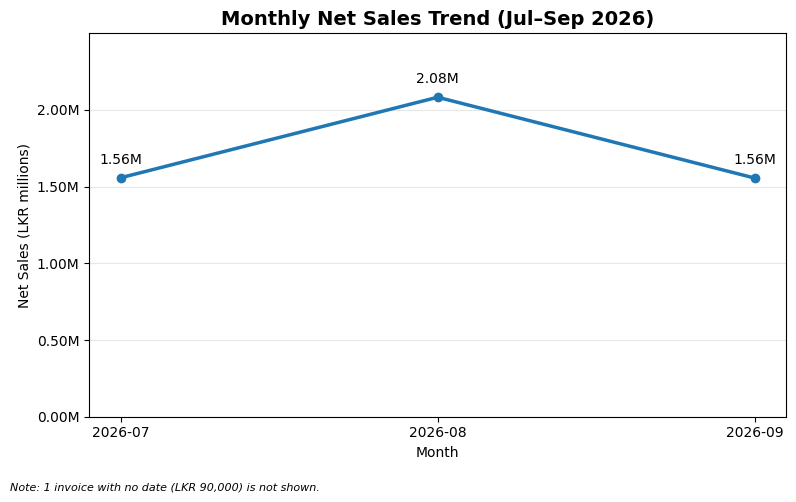

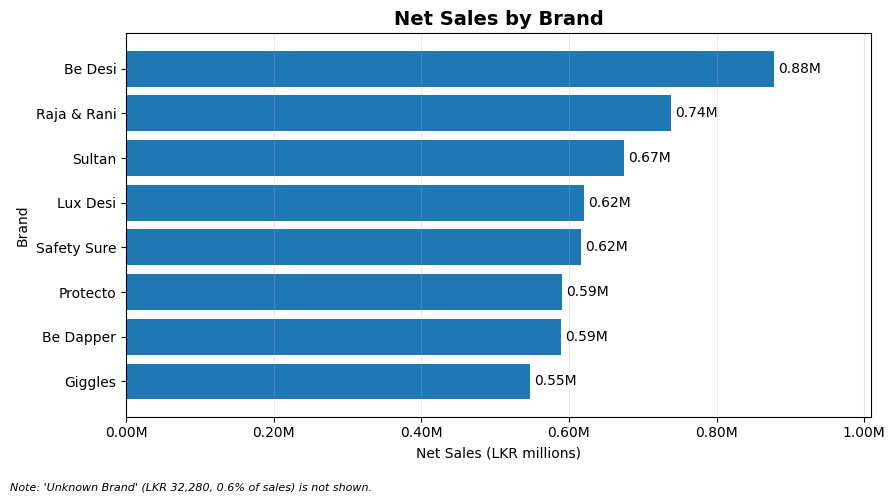

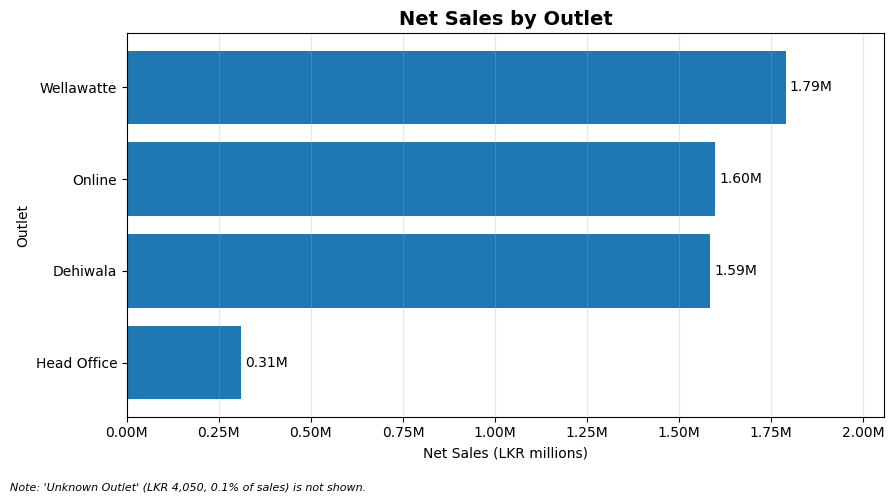

In [43]:
# --- Task 3: Charts ---
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs("outputs", exist_ok=True)

# Show axis numbers as millions with 2 decimals (e.g. 1,250,000 -> 1.25M)
def millions(x, pos):
    return f"{x/1e6:.2f}M"

# ---------- Chart 1: Monthly sales trend ----------
month_plot = monthly_summary[monthly_summary["Month"] != "No Date"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(month_plot["Month"], month_plot["Net_Sales_LKR"], marker="o", linewidth=2.5)

# Write the value above each point
for x, y in zip(month_plot["Month"], month_plot["Net_Sales_LKR"]):
    ax.annotate(f"{y/1e6:.2f}M", (x, y), textcoords="offset points", xytext=(0, 10), ha="center")

ax.set_title("Monthly Net Sales Trend (Jul–Sep 2026)", fontsize=14, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Net Sales (LKR millions)")
ax.yaxis.set_major_formatter(FuncFormatter(millions))
ax.set_ylim(0, month_plot["Net_Sales_LKR"].max() * 1.2)
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, 0.01, "Note: 1 invoice with no date (LKR 90,000) is not shown.", fontsize=8, style="italic")
plt.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig("outputs/monthly_sales_trend.png", dpi=150)
plt.show()


# ---------- Reusable bar chart ----------
def bar_chart(data, label_col, title, y_label, filename, note):
    """Horizontal bar chart of net sales, biggest bar at the top."""
    data = data.sort_values("Net_Sales_LKR")  # ascending, so the biggest ends up on top
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(data[label_col], data["Net_Sales_LKR"])
    ax.bar_label(bars, labels=[f"{v/1e6:.2f}M" for v in data["Net_Sales_LKR"]], padding=3)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Net Sales (LKR millions)")
    ax.set_ylabel(y_label)
    ax.xaxis.set_major_formatter(FuncFormatter(millions))
    ax.set_xlim(0, data["Net_Sales_LKR"].max() * 1.15)
    ax.grid(axis="x", alpha=0.3)
    fig.text(0.01, 0.01, note, fontsize=8, style="italic")
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    fig.savefig(filename, dpi=150)
    plt.show()

# ---------- Chart 2: Brand-wise net sales ----------
bar_chart(
    brand_summary[brand_summary["Brand"] != "Unknown Brand"],
    "Brand", "Net Sales by Brand", "Brand",
    "outputs/brand_net_sales.png",
    "Note: 'Unknown Brand' (LKR 32,280, 0.6% of sales) is not shown.",
)

# ---------- Chart 3: Outlet-wise net sales ----------
bar_chart(
    outlet_summary[outlet_summary["Outlet"] != "Unknown Outlet"],
    "Outlet", "Net Sales by Outlet", "Outlet",
    "outputs/outlet_net_sales.png",
    "Note: 'Unknown Outlet' (LKR 4,050, 0.1% of sales) is not shown.",
)

## Task 4: Automated Excel report
The function `build_report()` writes every summary and the cleaned data to `outputs/Retail_Sales_Report.xlsx` and formats it. Running the notebook again (Kernel → Restart & Run All) regenerates the report with no manual editing.

**Sheets:** KPI Summary, Brand Summary, Outlet Summary, Monthly Summary, Top 5 Brands, Top 5 Products, Discount Summary, Data Quality, Cleaned Data.
The Cleaned Data sheet keeps all 239 rows, including the 4 excluded rows, with their `DQ_Flag` and `Include_In_Analysis` columns. All other sheets use only the 235 included rows.

In [44]:
# --- Task 4: Automated Excel report ---
from openpyxl.styles import Font, PatternFill, Alignment

REPORT_FILE = "outputs/Retail_Sales_Report.xlsx"

def style_sheet(ws):
    """Make one worksheet look clean: header colour, number formats, column widths."""
    header_fill = PatternFill("solid", start_color="1F4E78")
    for cell in ws[1]:
        cell.font = Font(name="Arial", bold=True, color="FFFFFF")
        cell.fill = header_fill
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

    for column in ws.columns:
        header = str(column[0].value)

        # Choose a number format from the column name
        if header == "Discount_%":
            fmt = "0"
        elif "%" in header:
            fmt = "0.0"
        elif "LKR" in header:
            fmt = "#,##0.00"
        elif header in ("Units_Sold", "Invoice_Count", "Rows"):
            fmt = "#,##0"
        elif header == "Avg_Units_per_Invoice":
            fmt = "0.00"
        elif header == "Date":
            fmt = "yyyy-mm-dd"
        else:
            fmt = None

        for cell in column[1:]:
            cell.font = Font(name="Arial")
            if fmt:
                cell.number_format = fmt

        # Column width: based on the longest value, with a limit
        longest = max(len(str(c.value)) if c.value is not None else 0 for c in column)
        ws.column_dimensions[column[0].column_letter].width = min(max(longest + 3, 12), 45)

    ws.freeze_panes = "A2"   # keep the header visible when scrolling


def build_report(path=REPORT_FILE):
    """Write all summaries and the cleaned data to one formatted Excel file."""
    sheets = {
        "KPI Summary": kpi_summary,
        "Brand Summary": brand_summary,
        "Outlet Summary": outlet_summary,
        "Monthly Summary": monthly_summary,
        "Top 5 Brands": top5_brands,
        "Top 5 Products": top5_products,
        "Discount Summary": discount_summary,
        "Data Quality": dq_summary,
        "Cleaned Data": df,
    }
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        for name, table in sheets.items():
            table.to_excel(writer, sheet_name=name, index=False)
        for ws in writer.book.worksheets:
            style_sheet(ws)

        # KPI sheet: each row needs its own format (money vs whole numbers)
        kpi_ws = writer.book["KPI Summary"]
        for row, fmt in zip(range(2, 6), ["#,##0.00", "#,##0", "#,##0", "#,##0.00"]):
            kpi_ws.cell(row=row, column=2).number_format = fmt
        kpi_ws.column_dimensions["A"].width = 38
    print("Report saved:", path)

build_report()

# --- Check the file we just made ---
from openpyxl import load_workbook
wb = load_workbook(REPORT_FILE)
for ws in wb.worksheets:
    print(f"{ws.title:18} rows (without header): {ws.max_row - 1}")

Report saved: outputs/Retail_Sales_Report.xlsx
KPI Summary        rows (without header): 4
Brand Summary      rows (without header): 9
Outlet Summary     rows (without header): 5
Monthly Summary    rows (without header): 4
Top 5 Brands       rows (without header): 5
Top 5 Products     rows (without header): 5
Discount Summary   rows (without header): 6
Data Quality       rows (without header): 8
Cleaned Data       rows (without header): 239
